# 04 — BERT-base Fine-Tuning



## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)



In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

Reloaded 27 existing tuning_log rows from tuning_log.csv
Reloaded 9 existing final_results rows from final_results.csv


## 0. Reload Pipeline State from Notebook 1

In [3]:
import joblib

train_df = pd.read_csv('train_df.csv')
val_df = pd.read_csv('val_df.csv')
test_df = pd.read_csv('test_df.csv')

label_encoder = joblib.load('label_encoder.joblib')
class_weight_dict = joblib.load('class_weight_dict.joblib')
num_classes = len(label_encoder.classes_)

y_train = label_encoder.transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

print('Reloaded from Notebook 1:', train_df.shape, val_df.shape, test_df.shape, ' num_classes:', num_classes)

Reloaded from Notebook 1: (46697, 12) (10006, 12) (10007, 12)  num_classes: 6


In [4]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

## 14. BERT-base Fine-Tuning

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from datasets import Dataset

print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

BERT_MODEL_NAME = 'bert-base-uncased'
BERT_MAX_LEN = 256

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

def to_hf_dataset(df_split, labels):
    return Dataset.from_dict({'text': df_split['clean_summary'].tolist(), 'label': labels.tolist()})


train_ds = to_hf_dataset(train_df, y_train)
val_ds = to_hf_dataset(val_df, y_val)
test_ds = to_hf_dataset(test_df, y_test)

def tokenize_fn(batch):
    return bert_tokenizer(batch['text'], truncation=True, padding='max_length', max_length=BERT_MAX_LEN)

train_ds = train_ds.map(tokenize_fn, batched=True)
val_ds = val_ds.map(tokenize_fn, batched=True)
test_ds = test_ds.map(tokenize_fn, batched=True)

train_ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
val_ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
test_ds.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

/home/halululu/NLP-Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA available: True
GPU: NVIDIA GeForce RTX 3060


Map: 100%|██████████| 10007/10007 [00:00<00:00, 13938.60 examples/s]


In [ ]:
from sklearn.metrics import accuracy_score as _acc, f1_score as _f1

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {'accuracy': _acc(labels, preds), 'f1_macro': _f1(labels, preds, average='macro')}


bert_configs = [
    {'learning_rate': 5e-5, 'per_device_train_batch_size': 16, 'num_train_epochs': 2},
    {'learning_rate': 3e-5, 'per_device_train_batch_size': 16, 'num_train_epochs': 2},
    {'learning_rate': 2e-5, 'per_device_train_batch_size': 8,  'num_train_epochs': 3},  # smaller batch, more epochs
]

bert_trained_models = {}  # config string -> saved model directory (not the Trainer object -- that doesn't survive restarts)

for i, cfg in enumerate(bert_configs):
    save_path = bert_model_path(cfg)
    already_trained = os.path.exists(os.path.join(save_path, 'config.json'))

    if already_trained:
        print(f'--- BERT config {i+1}/{len(bert_configs)}: {cfg} -- already trained, loading {save_path} ---')
        model = AutoModelForSequenceClassification.from_pretrained(save_path)
    else:
        print(f'--- BERT config {i+1}/{len(bert_configs)}: {cfg} ---')
        model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL_NAME, num_labels=num_classes)

    args = TrainingArguments(
        output_dir=f'./bert_run_{i}',
        learning_rate=cfg['learning_rate'],
        per_device_train_batch_size=cfg['per_device_train_batch_size'],
        per_device_eval_batch_size=32,
        gradient_accumulation_steps=2 if cfg['per_device_train_batch_size'] == 8 else 1,  # keep effective batch ~16
        num_train_epochs=cfg['num_train_epochs'],
        eval_strategy='epoch',
        save_strategy='no',   # we save manually below, only once, after training -- not a checkpoint per epoch
        fp16=torch.cuda.is_available(),   # mixed precision -- essential for fitting BERT-base on 12GB
        logging_steps=100,
        seed=RANDOM_STATE,
        report_to='none',
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    if not already_trained:
        trainer.train()
        trainer.save_model(save_path)
        bert_tokenizer.save_pretrained(save_path)
        print(f'Trained and saved to {save_path}')

    val_metrics = trainer.evaluate()  # cheap either way -- just a forward pass over val_ds, not a retrain
    log_run('BERT-base', cfg, val_metrics['eval_accuracy'], val_metrics['eval_f1_macro'])
    bert_trained_models[str(cfg)] = save_path

--- BERT config 1/3: {'learning_rate': 5e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2} ---


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1391.51it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.613126,0.658288,0.760044,0.757901
2,0.477254,0.626656,0.774935,0.776304


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.19s/it]


Trained and saved to saved_models/bert/1732b31bba


...

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.234403,0.648366,0.759844,0.759063
2,1.003427,0.638047,0.765541,0.767926
3,0.917779,0.649374,0.768139,0.769951


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.83s/it]


Trained and saved to saved_models/bert/b213a48c00


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.917779,0.649374,3,0.768139,0.769951


BERT-base              {'learning_rate': 2e-05, 'per_device_train_batch_size': 8, 'num_train_epochs': 3} val_acc=0.7681  val_f1_macro=0.7700


In [7]:
tuning_log_df = pd.DataFrame(tuning_log)  # refresh with BERT runs included
bert_log = tuning_log_df[tuning_log_df['model'] == 'BERT-base']
bert_log

,model,config,val_accuracy,val_f1_macro
27,BERT-base,"{'learning_rate': 5e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2}",0.774935,0.776304
28,BERT-base,"{'learning_rate': 3e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2}",0.771237,0.771780
29,BERT-base,"{'learning_rate': 2e-05, 'per_device_train_batch_size': 8, 'num_train_epochs': 3}",0.768139,0.769951


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1374.22it/s]


Best BERT config: {'learning_rate': 5e-05, 'per_device_train_batch_size': 16, 'num_train_epochs': 2}  (val_f1_macro=0.7763)


=== BERT-base (test set) ===
Accuracy: 0.7602   Macro-F1: 0.7608   Weighted-F1: 0.7566
                                                        precision    recall  f1-score   support

                               Artificial Intelligence       0.71      0.70      0.71      1800
Computation and Language (Natural Language Processing)       0.83      0.85      0.84      1800
               Computer Vision and Pattern Recognition       0.85      0.90      0.88      1800
                                      Machine Learning       0.63      0.53      0.58      1800
                         Machine Learning (Statistics)       0.73      0.79      0.76      1800
                     Neural and Evolutionary Computing       0.80      0.82      0.81      1007

                                              accuracy                           0.76     10007
                                             macro avg       0.76      0.76      0.76     10007
                                          weigh

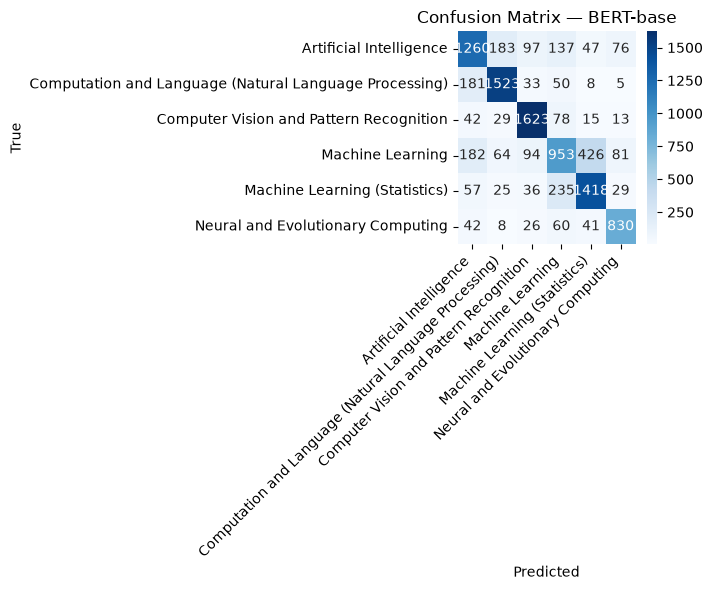

In [8]:
best_row = best_config_row(tuning_log_df, 'BERT-base')
best_cfg = parse_config(best_row['config'])
best_model_path = bert_trained_models.get(best_row['config']) or bert_model_path(best_cfg)
best_model = AutoModelForSequenceClassification.from_pretrained(best_model_path)
best_trainer = Trainer(model=best_model, compute_metrics=compute_metrics)  # eval-only Trainer, no training args needed
print(f'Best BERT config: {best_row["config"]}  (val_f1_macro={best_row["val_f1_macro"]:.4f})')

test_output = best_trainer.predict(test_ds)
test_pred = np.argmax(test_output.predictions, axis=1)

acc = accuracy_score(y_test, test_pred)
f1_macro = f1_score(y_test, test_pred, average='macro')
f1_weighted = f1_score(y_test, test_pred, average='weighted')
cm = confusion_matrix(y_test, test_pred)
report = classification_report(y_test, test_pred, target_names=label_encoder.classes_)

print('=== BERT-base (test set) ===')
print(f'Accuracy: {acc:.4f}   Macro-F1: {f1_macro:.4f}   Weighted-F1: {f1_weighted:.4f}')
print(report)

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix — BERT-base')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

record_final_result('BERT-base', acc, f1_macro, f1_weighted)